# 05 — Tier 2: weekly warning signs and the Shisper 2022 replay

**In plain words:** for the three special lakes (Shisper, Khurdopin, Passu), every week gets a colour:
* **green**: no warning sign;
* **amber**: the lake grew fast in 2 weeks, **or** it is unusually big for that lake during a heat spell;
* **red**: amber two measured weeks in a row, or very big during a strong heat spell;
* **no data**: the week was cloudy, so we cannot tell (never called "green").

The rules are simple on purpose: with a handful of floods per lake, a trained model cannot be trusted, but a
transparent rule can be checked by anyone.

**The honest test (the project's main result):**
1. The rule settings are **chosen using 2015–2021 only** and then **frozen** (saved with a timestamp).
2. The frozen rules are **replayed on 2022**: would they have warned **at least 7 days before** Shisper burst on
   **7 May 2022**? Then on **2023–2025**, which were also never used for choosing (Shisper burst again in 2025).
3. **False alarms** (warnings not followed by a flood) are counted for every lake and season. Passu, which did not
   burst in this period, shows how often the rules cry wolf.

| Output | What it is |
| --- | --- |
| `alerts.csv` | the colour and reasons for every lake and week, 2015–2025 (SPECS §3; the app's replay page) |
| `FROZEN_THRESHOLDS.json` | the chosen settings and when they were frozen, saved **before** 2022 is looked at |
| `tier2_events.csv`, `tier2_false_alarms.csv`, `tuning_table.csv` | the evidence |
| `metrics.json` | Tier 1 (from notebook 04) + Tier 2 together: the file the app serves |
| `fig_05_shisper_2022_replay.png`, `fig_05_all_events.png`, `run_info.json` | the replay figures |


## 0. Setup
The rules (`karaglof.rules`) are the tested code from the repository. The weekly table comes from the frozen dataset
(`data/features/lake_week.parquet`), the outbursts from `data/labels/events.csv`, the Tier 1 results from
`data/model/metrics_tier1.json`.

In [10]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/inamjadoon/KaraGlof.git"
REPO_DIR = "/content/KaraGlof"
if os.path.isdir(REPO_DIR):
    subprocess.run(["git", "-C", REPO_DIR, "pull", "-q"], check=True)
else:
    subprocess.run(["git", "clone", "-q", REPO_URL, REPO_DIR], check=True)
sys.path.insert(0, f"{REPO_DIR}/src")
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--oneline"],
                     capture_output=True, text=True).stdout)

4c5254a model: notebook 05, Tier 2 warning signs and the Shisper 2022 replay (awaiting Colab run)



In [11]:
import json
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
from matplotlib.patches import Patch

from karaglof import rules as kr

drive.mount("/content/drive")
OUT = Path("/content/drive/MyDrive/KaraGlof/05_tier2")
OUT.mkdir(parents=True, exist_ok=True)
DATA = Path(REPO_DIR) / "data"
TUNE_END = "2021-12-31"            # settings are chosen on 2015-2021 only
REPLAY = ("KG-HUN-363", "2022-05-07")   # Shisper, 7 May 2022
MIN_LEAD_DAYS = 7                  # PRD target: amber or red at least 7 days before drainage
COLORS = {"green": "#2ca02c", "amber": "#ff9f1c", "red": "#d62728", "no_data": "#c7c7c7"}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load the weekly table and the outbursts REPORT
Only these columns drive the rules: `area_km2` (weekly lake area), `area_change_2w_pct` (growth against the latest
measured area 2–4 weeks earlier) and `t2m_anomaly_c` (heat against the 1980–1999 normal).
`event_in_window` is the evaluation answer and is **never** given to the rules.

In [12]:
week = pd.read_parquet(DATA / "features" / "lake_week.parquet")
week["week_start"] = pd.to_datetime(week.week_start)
events = pd.read_csv(DATA / "labels" / "events.csv")
lakes = pd.read_csv(DATA / "labels" / "lakes.csv", keep_default_na=False)
names = dict(zip(lakes.lake_id, lakes.name, strict=True))
tier2_ids = sorted(week.lake_id.unique())
ev = events[events.lake_id.isin(tier2_ids) & (events.date >= "2015-01-01")].copy()
RULE_INPUTS = ["lake_id", "week_start", "area_km2", "area_change_2w_pct", "t2m_anomaly_c"]
rule_week = week[RULE_INPUTS]                              # event_in_window is NOT passed to the rules
assert "event_in_window" not in rule_week.columns
print(f"{len(week)} lake-weeks for {[names[i] for i in tier2_ids]}; "
      f"{week.area_km2.notna().mean():.0%} of weeks have a measured area")
print(ev.assign(lake=ev.lake_id.map(names))[["lake", "date", "date_certainty", "source"]]
      .assign(source=lambda d: d.source.str[:40]).to_string(index=False))

1722 lake-weeks for ['Passu', 'Shisper', 'Khurdopin']; 64% of weeks have a measured area
     lake       date date_certainty                                   source
Khurdopin 2017-07-28            day Lutzow & Veh GLOF database v4.2 (doi:10.
Khurdopin 2018-01-01           year Lutzow & Veh GLOF database v4.2 (doi:10.
Khurdopin 2018-04-01          month Lutzow & Veh GLOF database v4.2 (doi:10.
Khurdopin 2018-05-10            day Lutzow & Veh GLOF database v4.2 (doi:10.
Khurdopin 2019-05-10            day Lutzow & Veh GLOF database v4.2 (doi:10.
  Shisper 2019-06-22            day Lutzow & Veh GLOF database v4.2 (doi:10.
  Shisper 2020-01-01          month Lutzow & Veh GLOF database v4.2 (doi:10.
  Shisper 2020-05-29            day Lutzow & Veh GLOF database v4.2 (doi:10.
  Shisper 2021-05-01          month Lutzow & Veh GLOF database v4.2 (doi:10.
Khurdopin 2021-05-01          month Lutzow & Veh GLOF database v4.2 (doi:10.
  Shisper 2022-05-07            day Lutzow & Veh GLOF database v

## 2. Choose the settings on 2015–2021 and freeze them REPORT
`karaglof.rules.tune` tries 24 settings (`threshold_grid`: growth 15/25/50/100%, lake-size percentile 90/80, heat
+2/+1/+3 °C) on **2015–2021 only** and picks by a rule written down *before* any result was seen:
1. most day-dated outbursts warned **at least 7 days ahead**;
2. then **fewest false alarms**;
3. then **closest to the original SPECS values** (15%, p90, +2 °C).

The choice is saved with a timestamp in `FROZEN_THRESHOLDS.json` **before** 2022 is looked at. On any rerun the
saved file is loaded and nothing is re-tuned, so the 2022 replay can never influence the settings.

In [13]:
frozen_file = OUT / "FROZEN_THRESHOLDS.json"
if frozen_file.exists():
    frozen = json.loads(frozen_file.read_text())
    th = kr.Thresholds(**frozen["thresholds"])
    tuning = pd.read_csv(OUT / "tuning_table.csv")
    print(f"Thresholds were frozen on {frozen['frozen_utc']}: loading them, NOT re-tuning.")
else:
    tune_week = rule_week[rule_week.week_start <= TUNE_END]
    tune_events = ev[ev.date <= TUNE_END]
    th, tuning = kr.tune(tune_week, tune_events, kr.threshold_grid(), MIN_LEAD_DAYS)
    tuning.to_csv(OUT / "tuning_table.csv", index=False)
    frozen = {"frozen_utc": datetime.now(UTC).isoformat(timespec="seconds"), "thresholds": th.__dict__,
              "tuned_on": "2015-2021", "rule": "most outbursts warned >= 7 days ahead, then fewest false "
              "alarms, then closest to the SPECS starting values", "min_lead_days": MIN_LEAD_DAYS}
    frozen_file.write_text(json.dumps(frozen, indent=2))
    print(f"Thresholds chosen on 2015-2021 and frozen at {frozen['frozen_utc']}.")
print("\nTop of the tuning table (2015-2021 only):")
print(tuning.drop(columns=["order", "red_weeks_in_a_row", "percentile_red"]).head(8).round(1).to_string(index=False))
print("\nFROZEN:", th)

Thresholds were frozen on 2026-11-19T15:30:48+00:00: loading them, NOT re-tuning.

Top of the tuning table (2015-2021 only):
 growth_2w_pct  percentile_amber  anomaly_amber_c  anomaly_red_c  detected  outbursts  false_alarms  mean_lead_days
          25.0              90.0              3.0            4.0         2          5           172            11.0
          25.0              90.0              2.0            3.0         2          5           174            11.0
          25.0              90.0              1.0            2.0         2          5           176            11.0
          25.0              80.0              3.0            4.0         2          5           183            11.0
          15.0              90.0              3.0            4.0         2          5           189            11.0
          15.0              90.0              2.0            3.0         2          5           191            11.0
          25.0              80.0              2.0            3.

## 3. Weekly colours for 2015–2025 with the frozen settings

In [14]:
alerts = kr.assign_alert_levels(rule_week, th)
alerts["week_start"] = pd.to_datetime(alerts.week_start)
per_event, per_season = kr.evaluate(alerts, ev, MIN_LEAD_DAYS)
per_event["lake"] = per_event.lake_id.map(names)
per_event["period"] = np.select([per_event.date <= TUNE_END, per_event.date < "2023-01-01"],
                                ["tuning 2015-2021 (in-sample)", "REPLAY 2022 (frozen)"],
                                "after freeze 2023-2025 (frozen)")
per_season["lake"] = per_season.lake_id.map(names)
print(alerts.level.value_counts().to_string())

level
green      780
no_data    619
amber      185
red        138


## 4. Results REPORT
* **Per outburst:** the lead time (days between the first week of the warning run and the drainage) and whether it
  was at least 7 days. The tuning years are *in-sample* (the settings were chosen on them); **2022 and 2023–2025
  are the honest test.**
* **False alarms** per lake and season: amber/red weeks not followed by a flood. Weeks just before an outburst known
  only to the month cannot be judged and are left out.

In [15]:
print("Per outburst (day-dated only):")
print(per_event[["period", "lake", "date", "lead_time_days", "detected"]].to_string(index=False))
replay = per_event[(per_event.lake_id == REPLAY[0]) & (per_event.date == REPLAY[1])].iloc[0]
print(f"\nSHISPER 2022 REPLAY: lead time = {replay.lead_time_days} days -> "
      f"{'WARNED at least 7 days ahead' if replay.detected else 'NOT warned 7 days ahead'}")

fa = per_season.assign(period=np.where(per_season.year <= 2021, "2015-2021", "2022-2025"))
print("\nFalse alarms (amber/red weeks not followed by a flood), per lake and period:")
print(fa.groupby(["lake", "period"])[["raised_weeks", "false_alarms"]].sum().to_string())
print("\nper season (mean per lake-year):",
      fa.groupby("period").false_alarms.mean().round(1).to_dict())

Per outburst (day-dated only):
                         period      lake       date  lead_time_days  detected
   tuning 2015-2021 (in-sample) Khurdopin 2017-07-28             NaN     False
   tuning 2015-2021 (in-sample) Khurdopin 2018-05-10             NaN     False
   tuning 2015-2021 (in-sample) Khurdopin 2019-05-10            11.0      True
   tuning 2015-2021 (in-sample)   Shisper 2019-06-22             NaN     False
   tuning 2015-2021 (in-sample)   Shisper 2020-05-29            11.0      True
           REPLAY 2022 (frozen)   Shisper 2022-05-07             NaN     False
after freeze 2023-2025 (frozen)   Shisper 2025-08-10             NaN     False

SHISPER 2022 REPLAY: lead time = nan days -> NOT warned 7 days ahead

False alarms (amber/red weeks not followed by a flood), per lake and period:
                     raised_weeks  false_alarms
lake      period                               
Khurdopin 2015-2021            75            71
          2022-2025            55            

## 5. The Shisper 2022 replay figure REPORT
Top: weekly lake area (dots; gaps = cloudy weeks). Middle: weekly temperature anomaly. Bottom: the frozen alert
colour of each week. The red line is the outburst (7 May 2022).

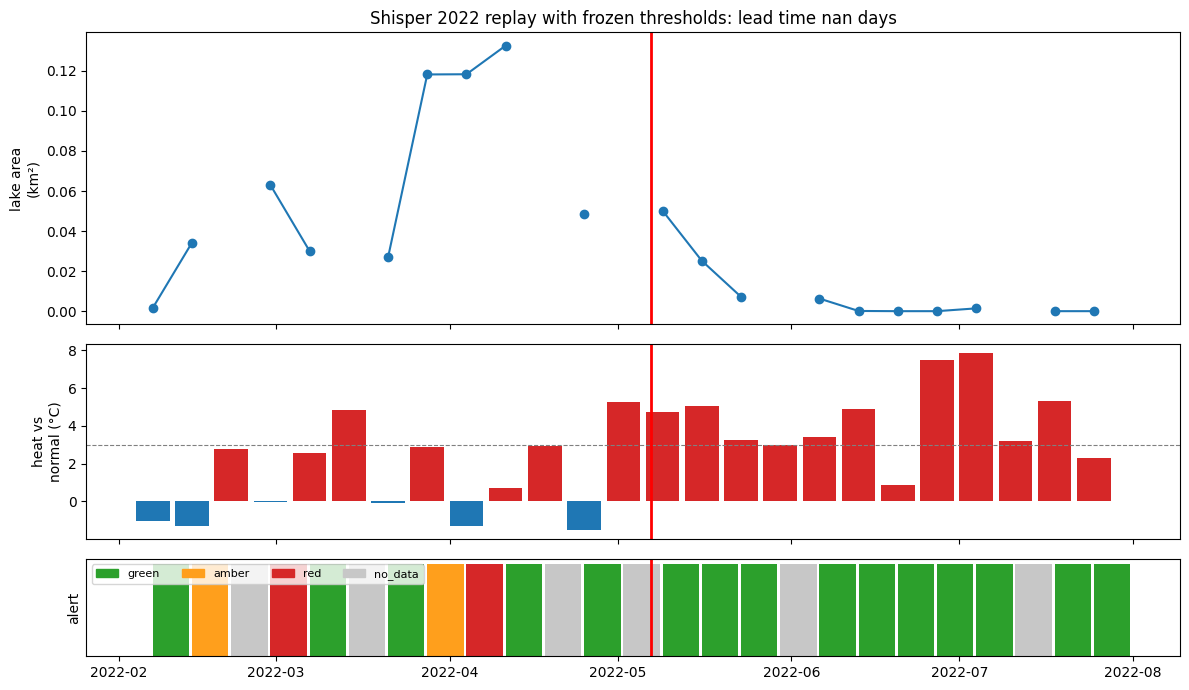

In [16]:
def replay_figure(lake_id, date, start, end, ax_area, ax_heat, ax_strip, title):
    w = week[(week.lake_id == lake_id) & week.week_start.between(start, end)]
    a = alerts[(alerts.lake_id == lake_id) & alerts.week_start.between(start, end)]
    ax_area.plot(w.week_start, w.area_km2, marker="o", color="#1f77b4")
    ax_area.set_ylabel("lake area\n(km²)")
    ax_area.set_title(title)
    ax_heat.bar(w.week_start, w.t2m_anomaly_c, width=6, color=np.where(w.t2m_anomaly_c > 0, "#d62728", "#1f77b4"))
    ax_heat.axhline(th.anomaly_amber_c, ls="--", color="grey", lw=0.8)
    ax_heat.set_ylabel("heat vs\nnormal (°C)")
    ax_strip.bar(a.week_start, 1, width=6.5, color=a.level.map(COLORS), align="edge")
    ax_strip.set_yticks([])
    ax_strip.set_ylabel("alert")
    for ax in (ax_area, ax_heat, ax_strip):
        ax.axvline(pd.Timestamp(date), color="red", lw=2)

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2, 1]})
replay_figure(*REPLAY, "2022-02-01", "2022-07-31", *axes,
              f"Shisper 2022 replay with frozen thresholds: lead time {replay.lead_time_days} days")
axes[2].legend(handles=[Patch(color=c, label=k) for k, c in COLORS.items()], ncol=4, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "fig_05_shisper_2022_replay.png", dpi=150)
plt.show()

## 6. All day-dated outbursts 2015–2025 (figure) REPORT

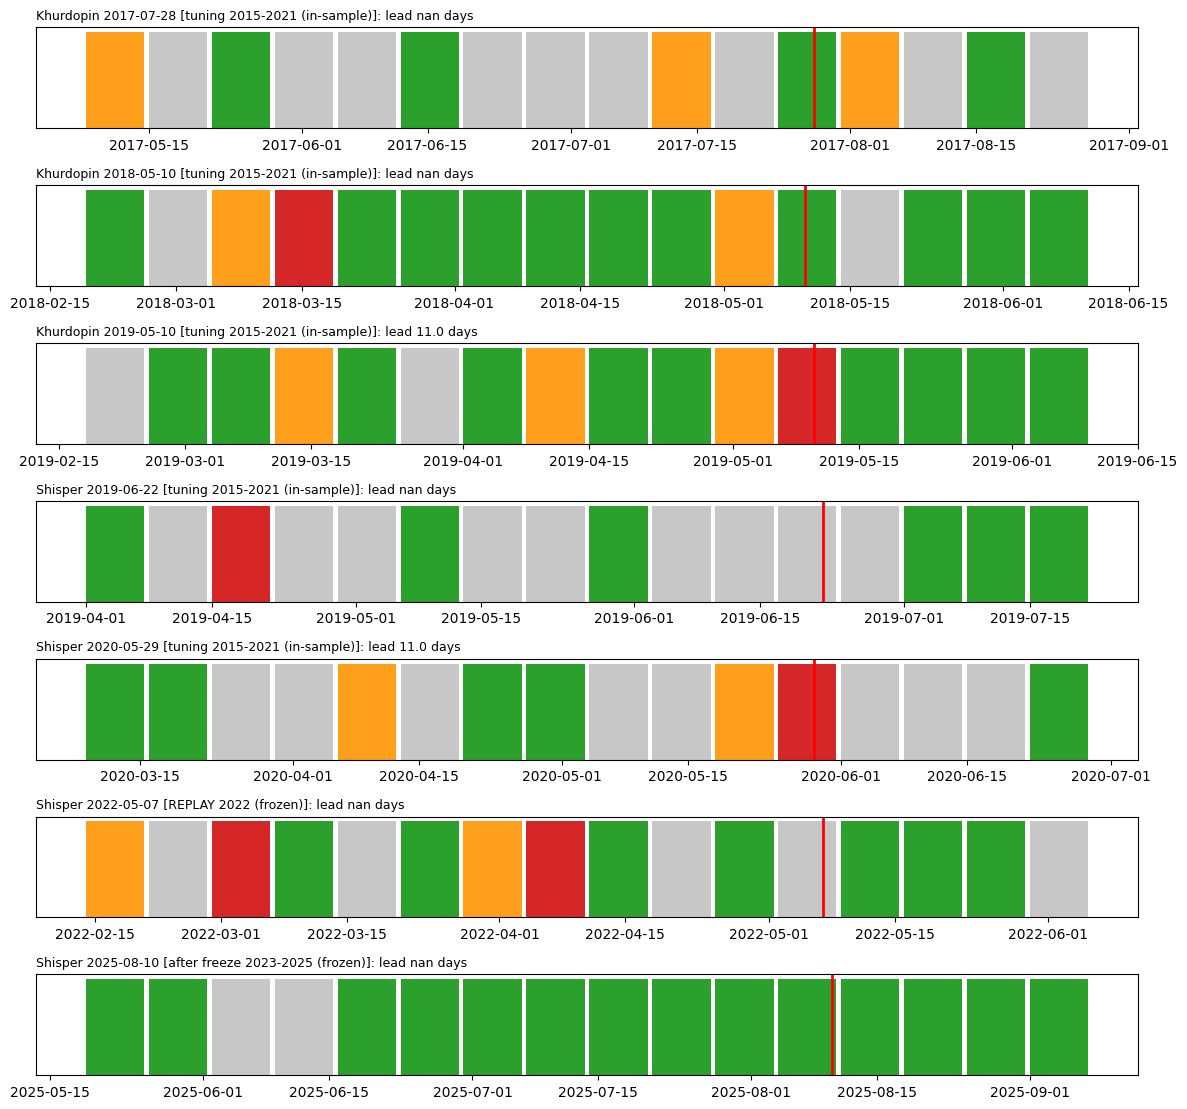

In [17]:
rows = per_event.reset_index(drop=True)
fig, axes = plt.subplots(len(rows), 1, figsize=(12, 1.6 * len(rows)), squeeze=False)
for ax, r in zip(axes[:, 0], rows.itertuples(), strict=True):
    d = pd.Timestamp(r.date)
    a = alerts[(alerts.lake_id == r.lake_id) & alerts.week_start.between(d - pd.Timedelta(days=84), d + pd.Timedelta(days=28))]
    ax.bar(a.week_start, 1, width=6.5, color=a.level.map(COLORS), align="edge")
    ax.axvline(d, color="red", lw=2)
    ax.set_yticks([])
    ax.set_title(f"{r.lake} {r.date} [{r.period}]: lead {r.lead_time_days} days", fontsize=9, loc="left")
fig.tight_layout()
fig.savefig(OUT / "fig_05_all_events.png", dpi=150)
plt.show()

## 7. Save `alerts.csv` and the combined `metrics.json`
`metrics.json` = the Tier 1 part from notebook 04 plus the Tier 2 part. Its `tier2.cases` list feeds the app's
`/cases` endpoint (one case per day-dated outburst).

In [18]:
out_alerts = alerts.assign(week_start=alerts.week_start.dt.strftime("%Y-%m-%d"))[["lake_id", "week_start", "level", "reasons"]]
out_alerts.to_csv(OUT / "alerts.csv", index=False)
per_event.to_csv(OUT / "tier2_events.csv", index=False)
per_season.to_csv(OUT / "tier2_false_alarms.csv", index=False)

season_fa = per_season.set_index(["lake_id", "year"]).false_alarms
cases, seen = [], {}
for r in per_event.itertuples():
    base = f"{r.lake.lower()}-{r.date[:4]}"
    seen[base] = seen.get(base, 0) + 1
    cases.append({"case_id": base if seen[base] == 1 else f"{base}-{seen[base]}", "lake_id": r.lake_id,
                  "event_date": r.date, "lead_time_days": None if pd.isna(r.lead_time_days) else int(r.lead_time_days),
                  "false_alarms": int(season_fa.get((r.lake_id, int(r.date[:4])), 0)), "period": r.period})

metrics = json.loads((DATA / "model" / "metrics_tier1.json").read_text())
metrics["tier2"] = {
    "thresholds": th.__dict__, "thresholds_frozen_before_replay": True, "frozen_utc": frozen["frozen_utc"],
    "tuned_on": "2015-2021", "min_lead_days": MIN_LEAD_DAYS,
    "replay_2022": {"lake_id": REPLAY[0], "event_date": REPLAY[1],
                    "lead_time_days": None if pd.isna(replay.lead_time_days) else int(replay.lead_time_days),
                    "warned_at_least_7_days": bool(replay.detected)},
    "false_alarms_per_lake_season": fa.groupby("period").false_alarms.mean().round(2).to_dict(),
    "weeks_with_data_share": float(week.area_km2.notna().mean()),
    "cases": cases,
}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))
(OUT / "run_info.json").write_text(json.dumps({"notebook": "05_tier2_cases",
                                               "run_utc": datetime.now(UTC).isoformat(timespec="seconds"),
                                               "pandas": pd.__version__}, indent=2))
print(json.dumps(metrics["tier2"]["replay_2022"], indent=2))
print(sorted(p.name for p in OUT.iterdir()))

{
  "lake_id": "KG-HUN-363",
  "event_date": "2022-05-07",
  "lead_time_days": null,
  "warned_at_least_7_days": false
}
['FROZEN_THRESHOLDS.json', 'alerts.csv', 'fig_05_all_events.png', 'fig_05_shisper_2022_replay.png', 'metrics.json', 'run_info.json', 'tier2_events.csv', 'tier2_false_alarms.csv', 'tuning_table.csv']
